# 05 · Visualizaciones, reporte e implicaciones

**Objetivo:** Mostrar a revenue management y category management cómo se comporta en el anaquel la arquitectura de precios por tamaño de marcas líderes, y dónde se rompe.

**Pregunta:** ¿Cómo se comunica el hallazgo y qué hace cada audiencia?

Convenciones: **rojo ▼** = el tamaño grande cuesta menos por unidad (lo esperado); **verde ▲** = cuesta más
(escalón roto); gris = sin cambio claro; dorado = referencia.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import entorno
entorno.setup()
import profeco, tablas, pares, estadistica as E, charts as C
import escalera as S
PROC, META, CHARTS, SOCIAL = entorno.PROC, entorno.META, entorno.CHARTS, entorno.SOCIAL
CFG = entorno.config()
reg = entorno.registrar
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 90)
pts, st, cat = S.load()
REPS = 500
p = pd.read_csv(PROC / "escalones.csv")
SEL = json.loads((META / "parametros.json").read_text(encoding="utf-8"))["seleccionadas"]
import graficas as G, reporte, plantillas, re
res = entorno.cifras()
lp = pd.read_csv(PROC / "precio_unidad_por_tamano.csv")
be = pd.read_csv(PROC / "rupturas_por_escalon.csv")
bf = pd.read_csv(PROC / "rupturas_por_formato.csv")
bm = pd.read_csv(PROC / "rupturas_por_marca.csv", index_col=0)

## Gráfica principal: escaleras de precio por tamaño

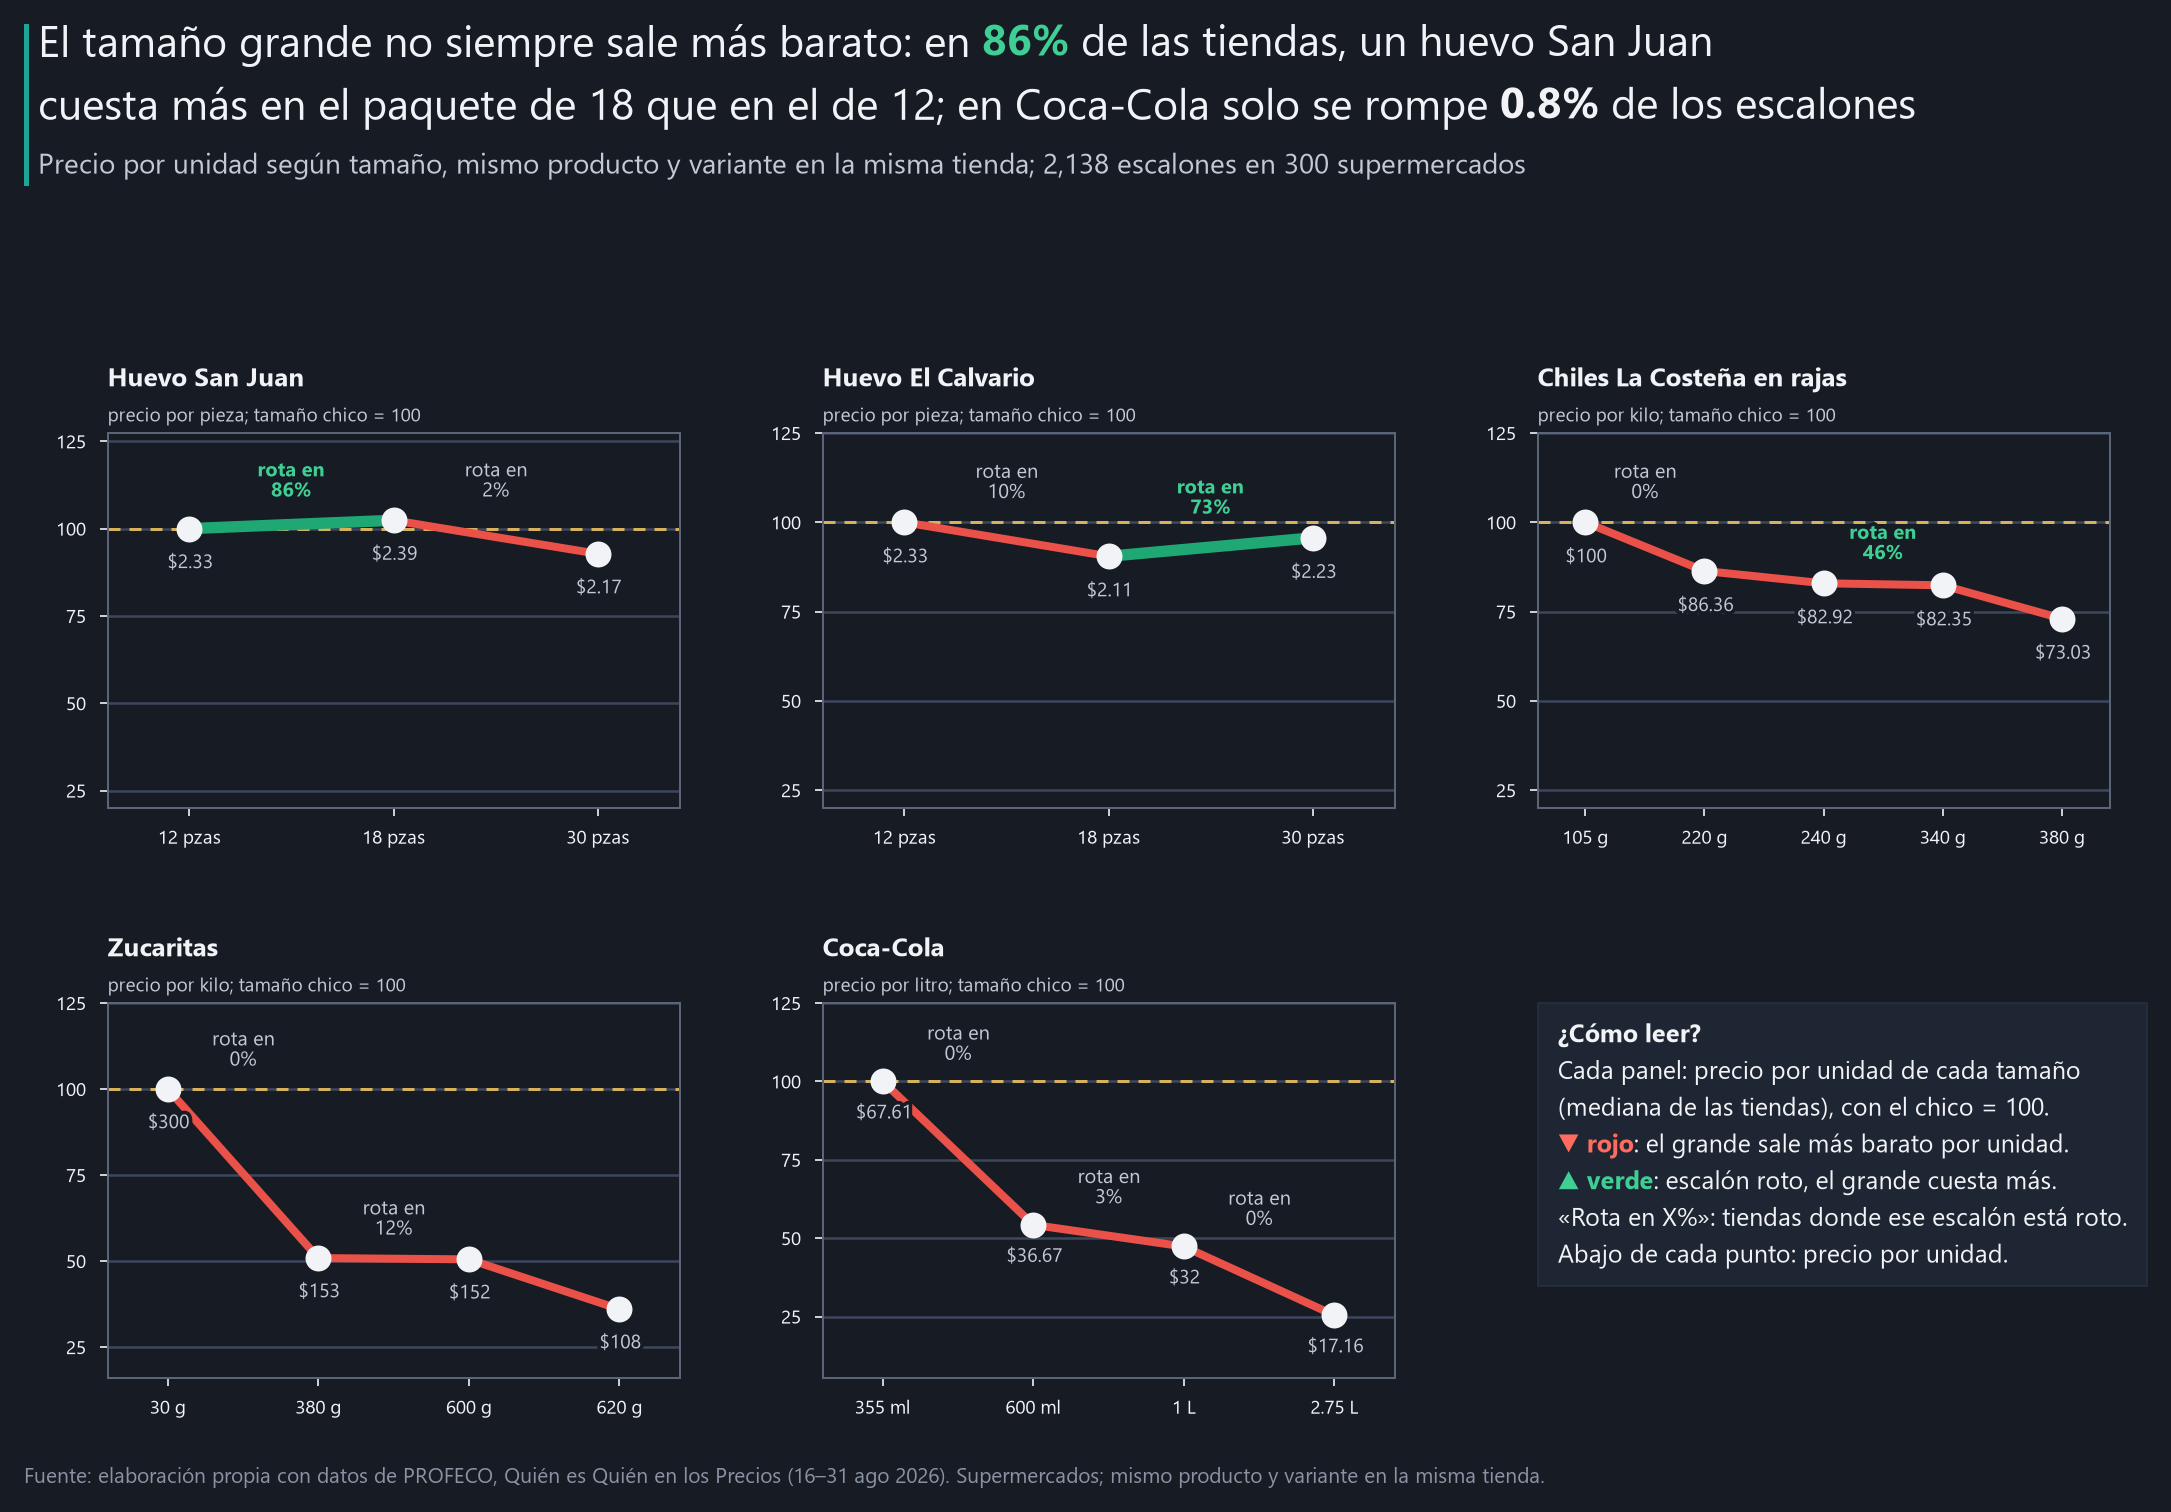

In [2]:
G.ladders(lp, be, SEL, res, CHARTS / "01_escaleras_por_tamano.png", svg=True); plt.show()

### Versiones para publicar (1280×720 y 1080×1350)

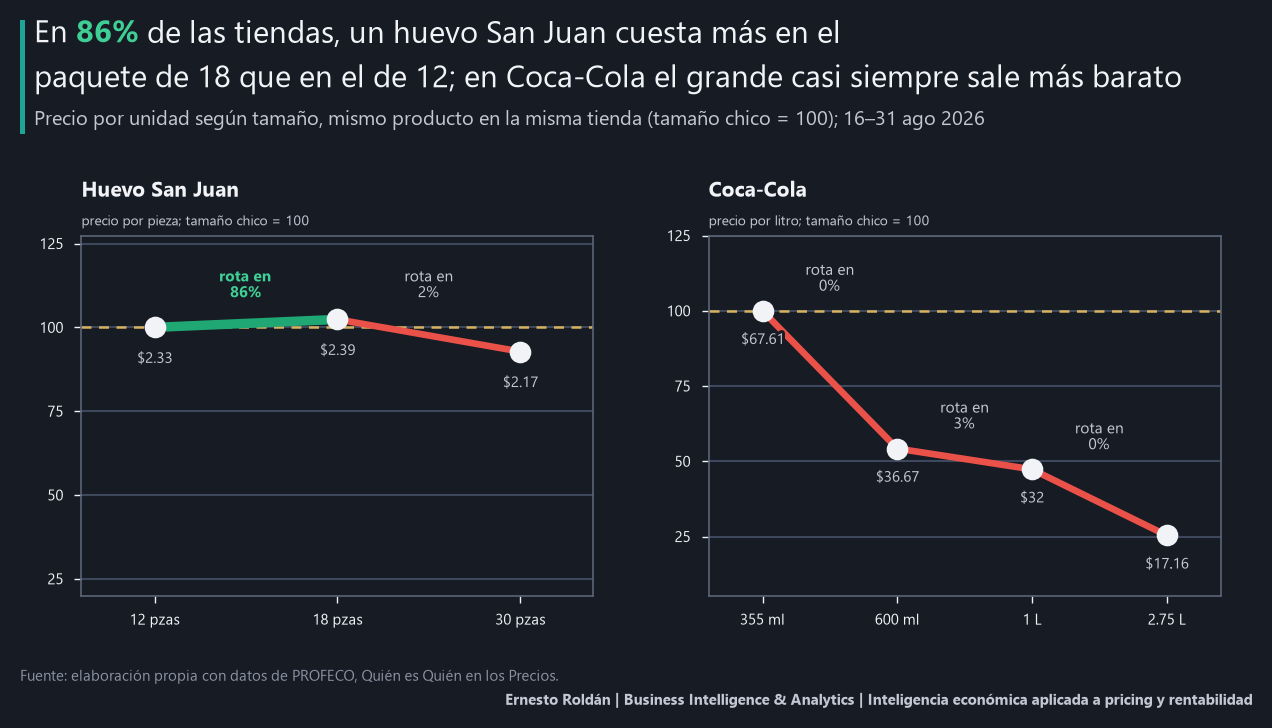

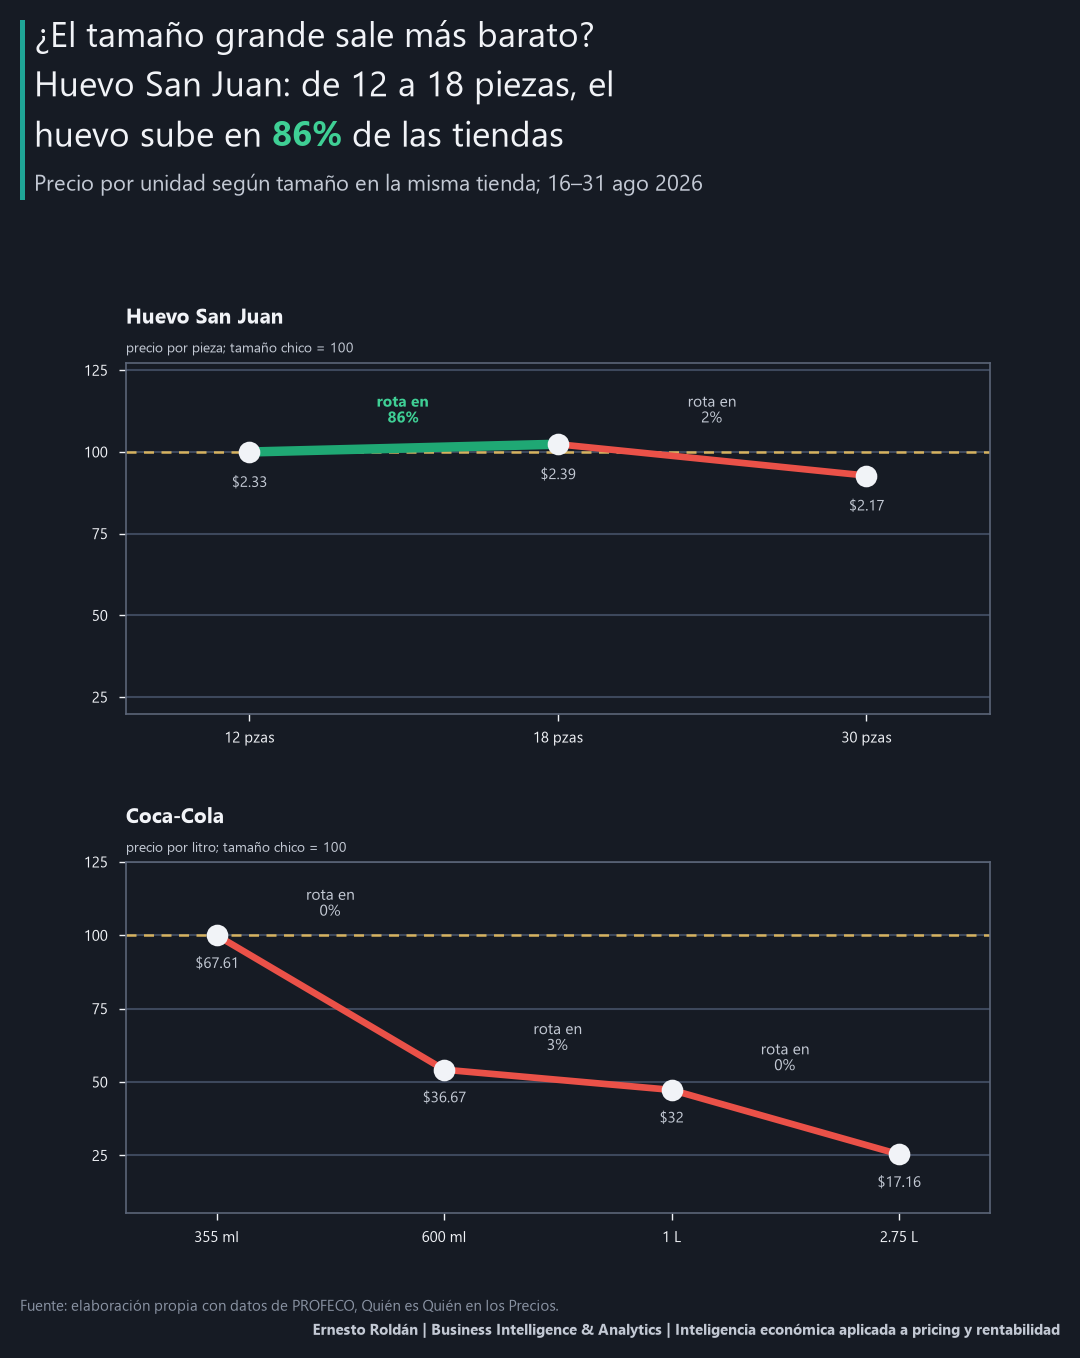

In [3]:
G.ladders_social(lp, be, res, "horizontal", SOCIAL / "01_escaleras_1280x720.png"); plt.show()
G.ladders_social(lp, be, res, "vertical", SOCIAL / "01_escaleras_1080x1350.png"); plt.show()

## Complementarias

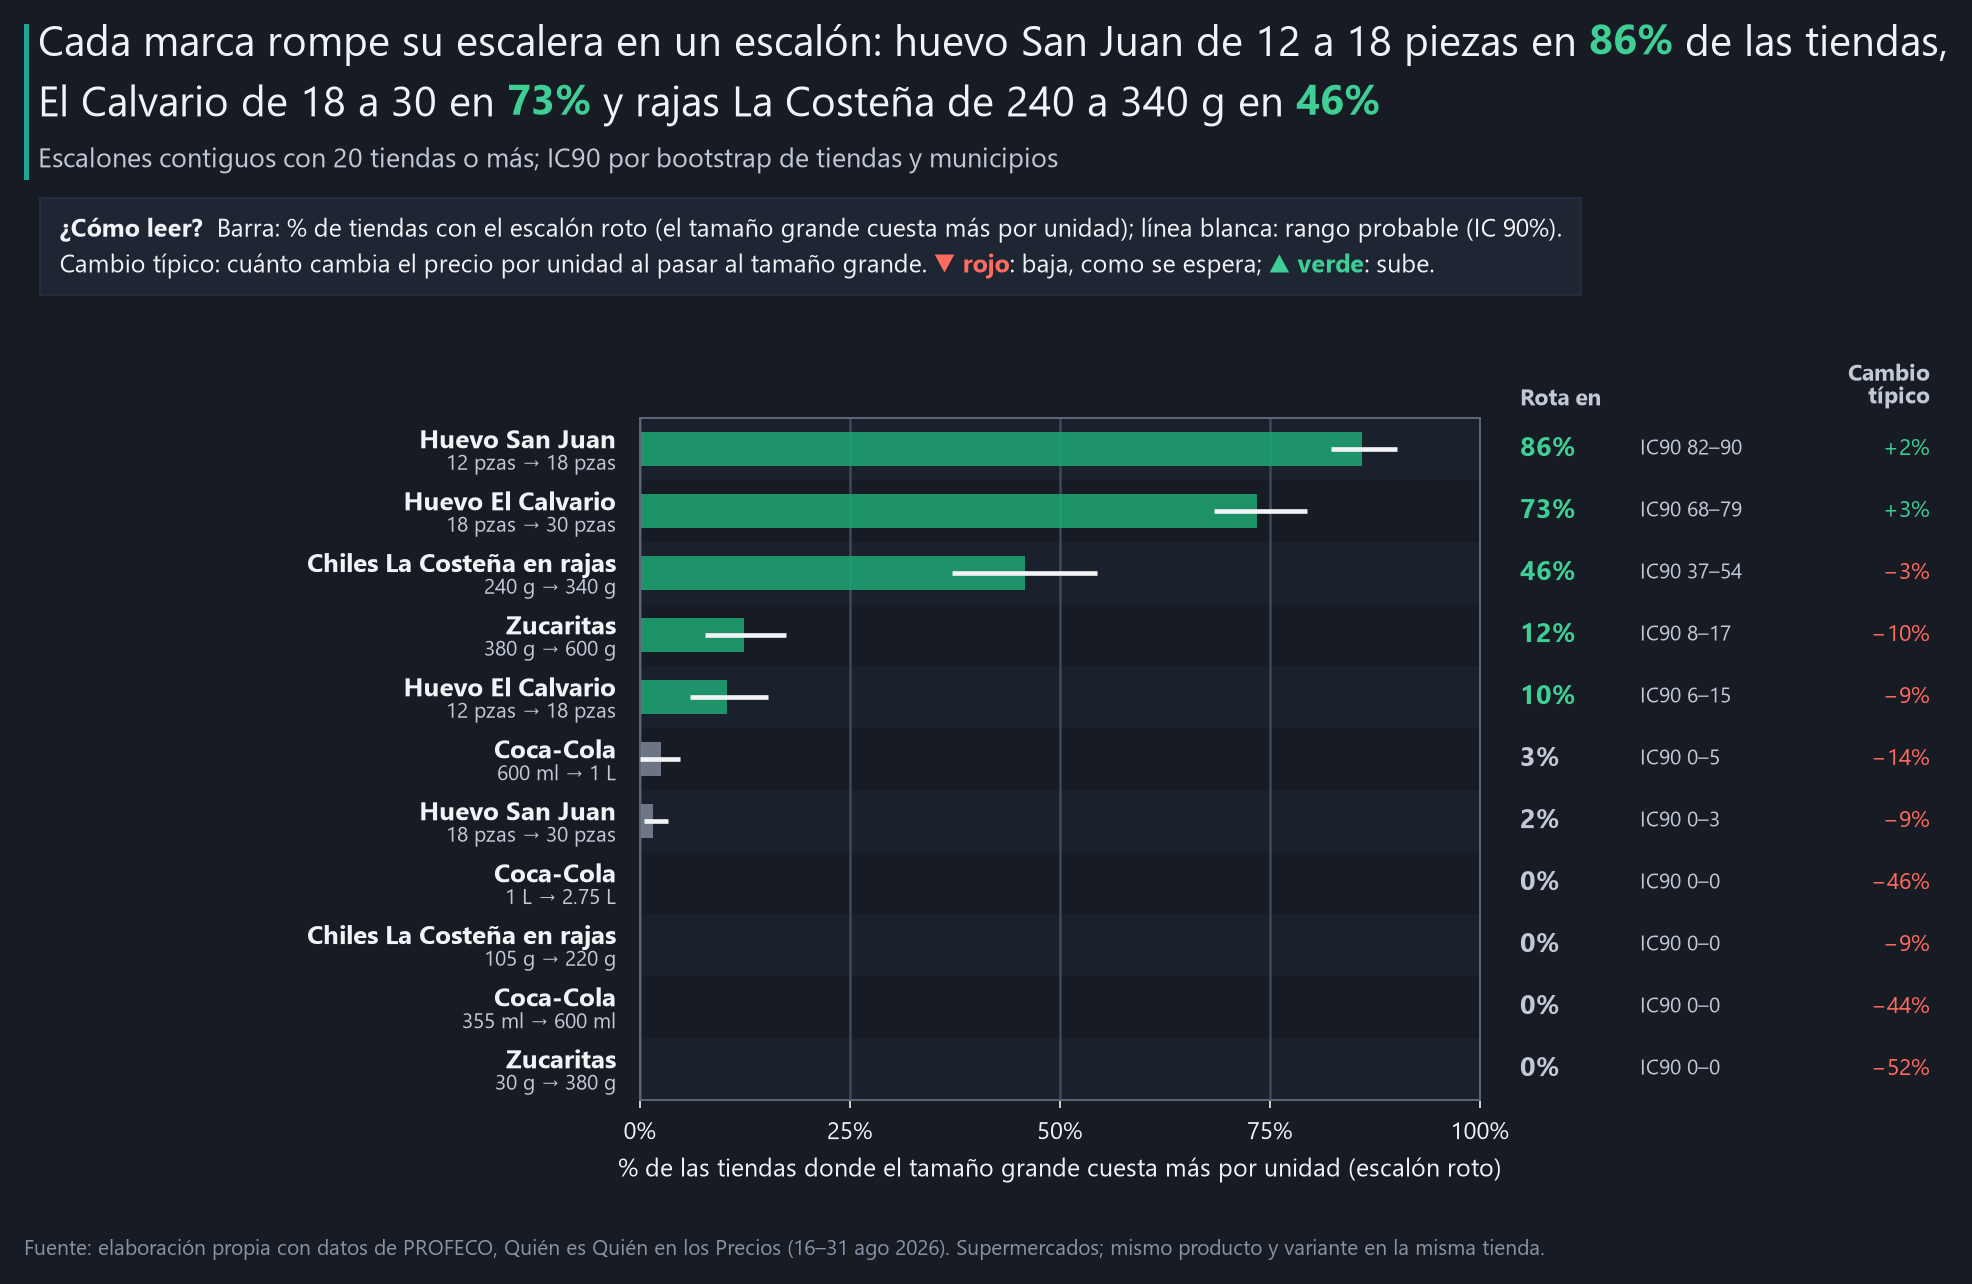

In [4]:
G.broken_by_step(be, res, CHARTS / "02_rupturas_por_escalon.png"); plt.show()

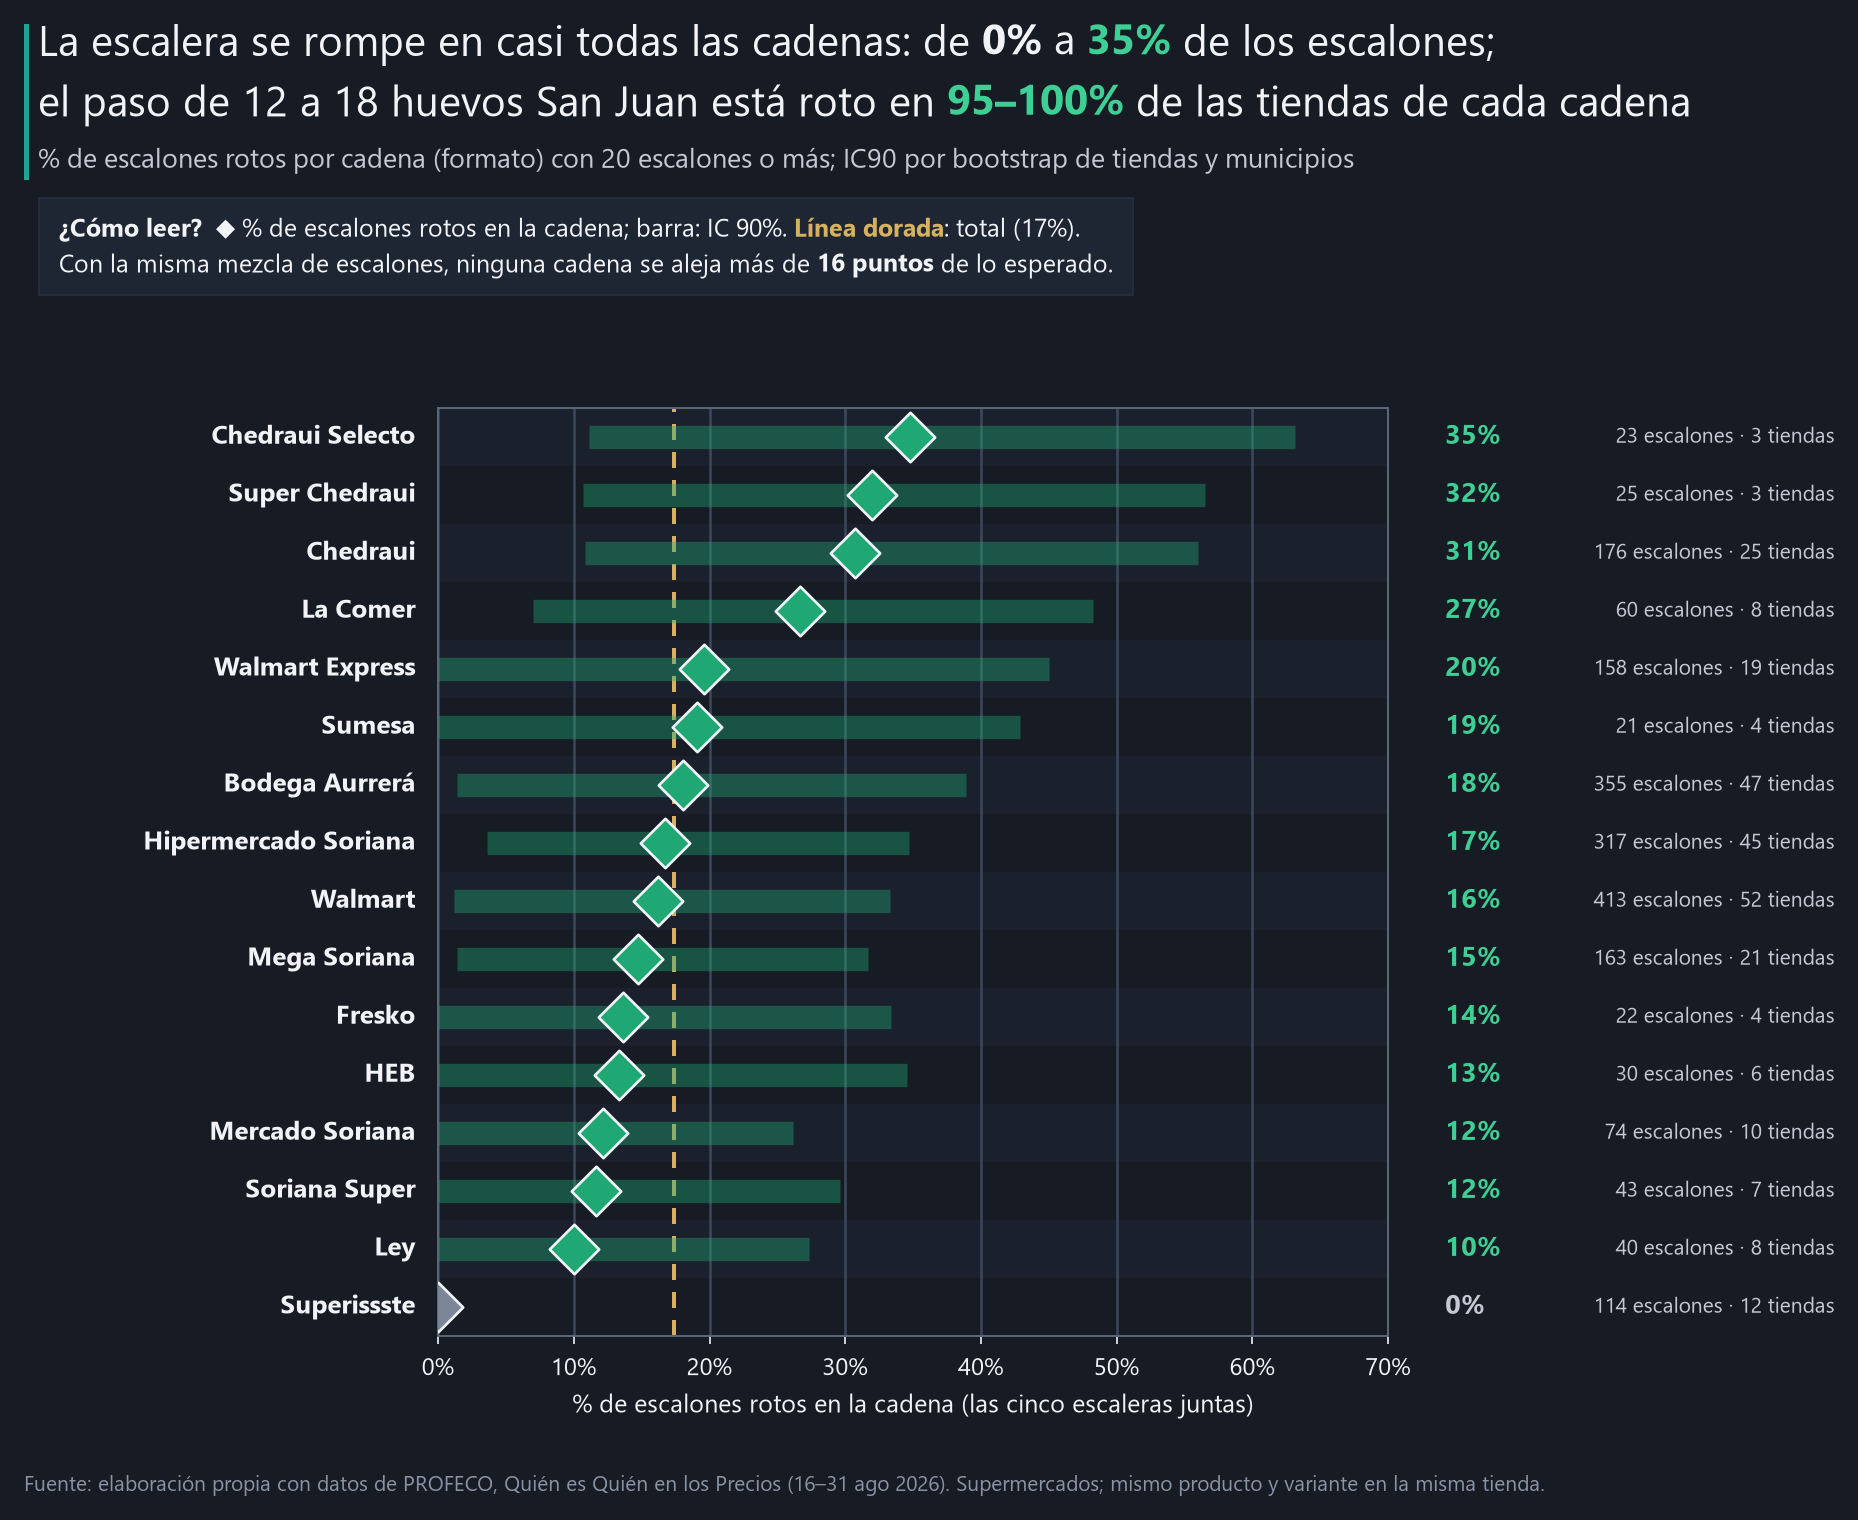

In [5]:
G.broken_by_format(bf, res, CHARTS / "03_rupturas_por_formato.png"); plt.show()

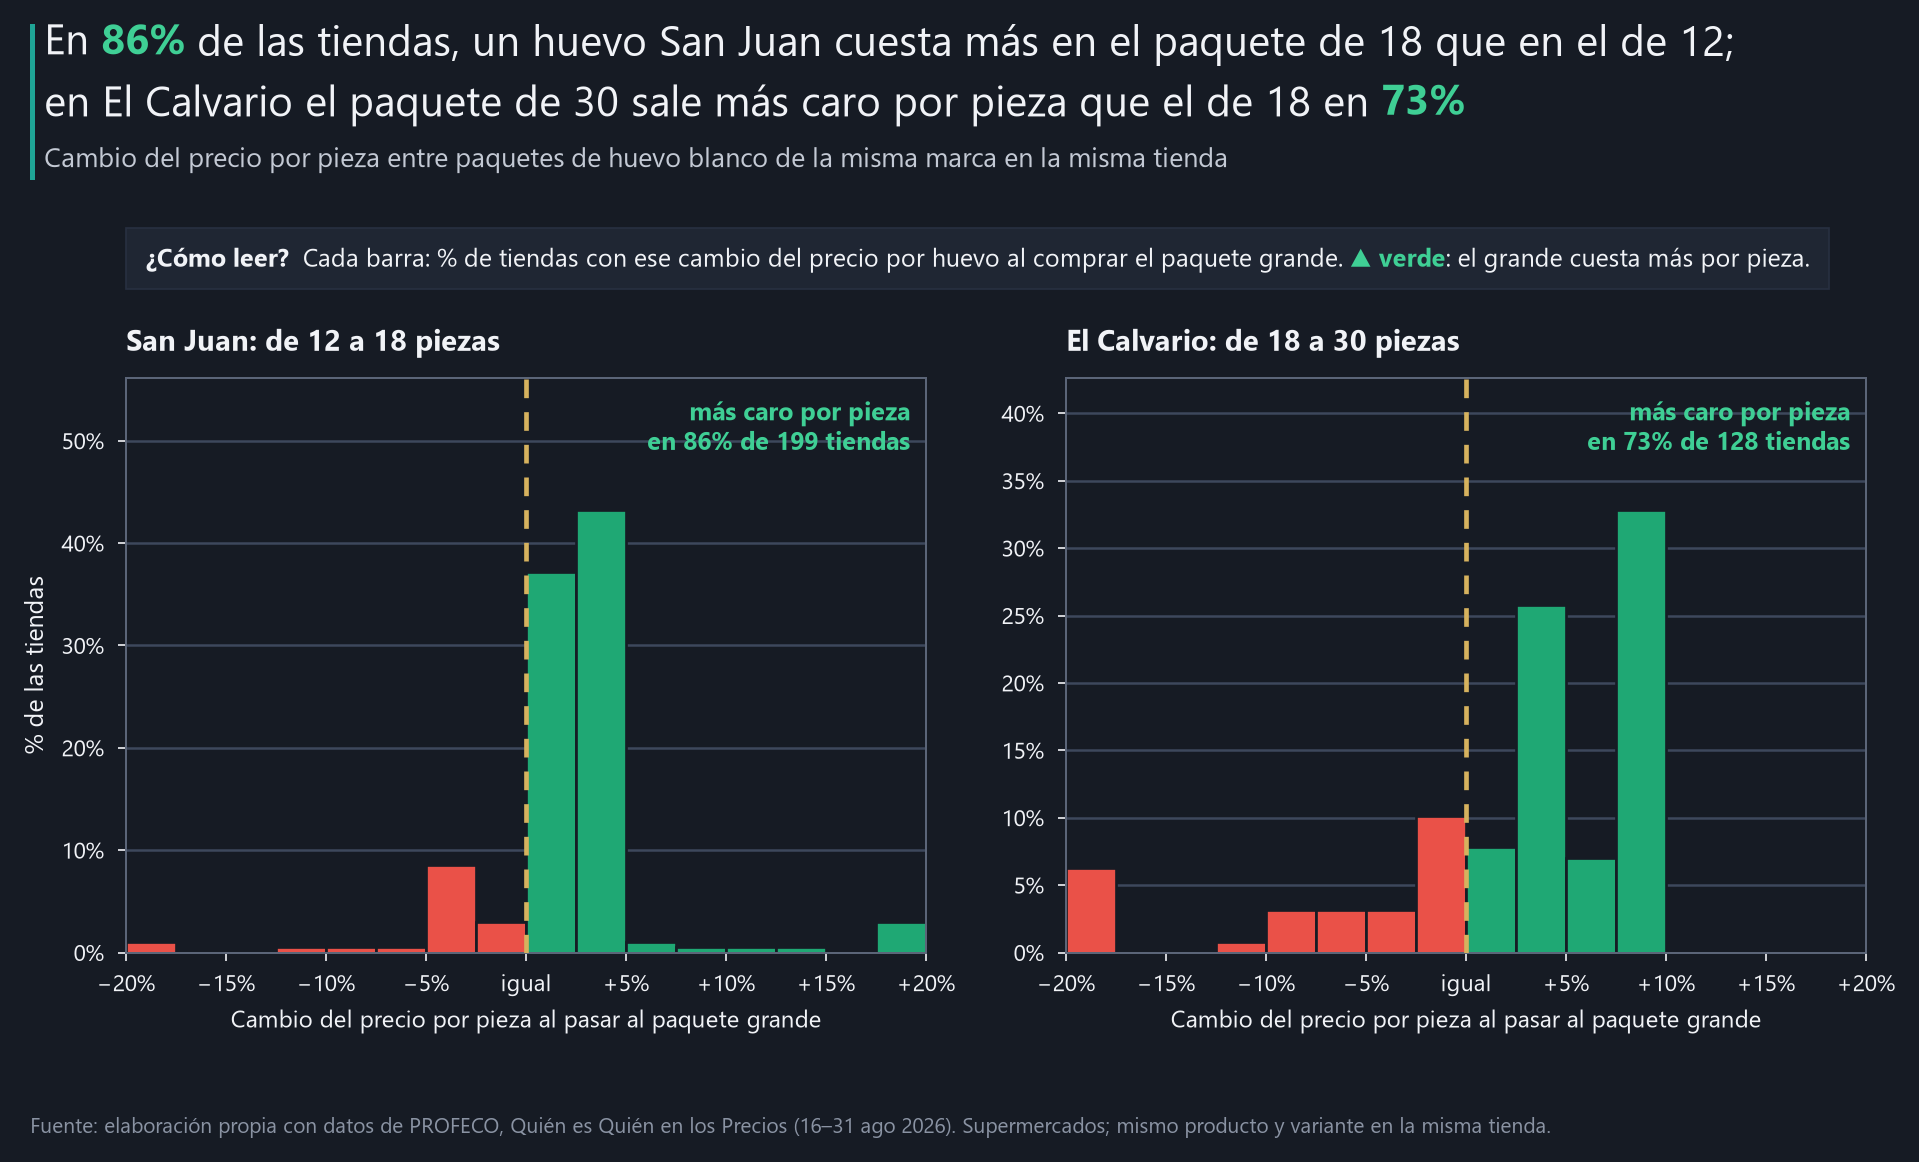

In [6]:
G.egg_case(p, res, CHARTS / "04_huevo_12_vs_18.png"); plt.show()

## Reporte HTML y README

In [7]:
GALERIA = [(g_["titulo"], g_["pie"], CHARTS / g_["archivo"]) for g_ in CFG["graficas"]]
out = reporte.build(be, bf, bm, res, CFG, GALERIA, ROOT / "docs/index.html")
print(out, f"{out.stat().st_size / 1e6:.1f} MB")
estructura = (ROOT / "src/estructura.md").read_text(encoding="utf-8")
(ROOT / "README.md").write_text(plantillas.readme(CFG, res, estructura), encoding="utf-8")
txt = (ROOT / "README.md").read_text(encoding="utf-8")
assert not re.search(r"\{[a-z][a-z0-9_]*(:[^}]*)?\}", txt), re.findall(r"\{[a-z][a-z0-9_]*(?::[^}]*)?\}", txt)[:5]
print("README actualizado")

C:\Users\THINKPAD\Documents\Documentos\analisis economicos\20octubre26\mexico-arquitectura-precio-tamano\docs\index.html 6.0 MB
README actualizado


## Qué hacer con esto

In [8]:
for aud, acc in CFG["readme"]["acciones"].items():
    display(Markdown(f"**{aud}**\n\n" + "\n".join(f"- {plantillas.render(a, res)}" for a in acc)))

**Revenue management de una marca**

- **Audite el escalón, no la marca.** La ruptura se concentra en un paso: 12 a 18 huevos (86% de las tiendas), 18 a 30 (73%), 240 a 340 g de rajas (46%). Revise el precio de lista de esos tamaños.
- **Si la ruptura está en todas las cadenas, el origen es su lista de precios.** El escalón de 12 a 18 huevos San Juan está roto en 95–100% de las tiendas de cada cadena.
- **Copie la disciplina de Coca-Cola:** cada tamaño más grande baja con claridad el precio por litro, y solo 0.8% de los escalones se rompe.

**Category management de una cadena**

- **Revise el anaquel con el precio por unidad.** Un escalón roto hace que el cliente informado compre el tamaño chico, o que el que no compara pague de más.
- **Marque los escalones planos y rotos en su sistema de precios.** 9% de los escalones son planos (descuento menor a 5%) y 17% están rotos.
- **Use la etiqueta de precio por unidad como herramienta, no como trámite:** es la que hace visible la escalera.

**Analista comercial**

- **Defina la variante antes de comparar tamaños.** Bimbo y los yoghurts parecen tener 3 tamaños, pero mezclan pan tostado con pan de caja y vaso con bebible.
- **Reporte por escalón y por tamaños contiguos.** El promedio por marca mezcla escalones sanos con rotos y su rango probable es muy amplio.